### 主成分分析



主成分分析是最常用的降维和数据压缩算法之一。该算法旨在寻找一些向量$u$将原始数据$x$投影到低维子空间中。在数学中，我们希望在几何中$||u||_2 = 1$的条件下最大化$| x^Tu||_2$。可以用拉格朗日法求解凸优化，很容易看出$u$仅仅是$x$协方差矩阵的一个特征向量。在选择上$k$特征向量后，我们将得到$k$维子空间中的投影$x^Tu$，而不是原始的$n$维空间。

先导入需要的库：

In [1]:
import sklearn.decomposition
import sklearn.datasets
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg

### 计算Covariance矩阵的本征向量

In [2]:
#compute eigenvector of covariance matrix
def self_pca_sigma(data,num_of_dims):

    #numbers of eigenvectors do not exceed the number of features
    assert num_of_dims<=data.shape[1],"the transformed dimension should be smaller than the original"

    #standardize the data by minus mean and divided by std
    #equivalent to z score in statistics
    #equivalent to scipy.stats.zscore or sklearn.preprocessing.scale
    z=np.divide(data-data.mean(axis=0),data.std(axis=0))

    #get covariance matrix
    #due to rounding errors
    #it doesnt equal to np.cov(z.T)
    sigma=z.T@z/z.shape[0]

    #get eigenvectors
    #please note eigenvectors are in the columns rather than rows
    eigvals,eigvecs=np.linalg.eig(sigma)
    
    return eigvecs

In [3]:
#our fav iris data
iris=sklearn.datasets.load_iris()

#initialize
num_of_dims=2

#get z score to maintain consistency with self implementations
#although this is unnecessary for iris dataset
#as i have never done this in other notebooks
#because all features are in cm
#unit variance doesnt really hurt, does it
z=sklearn.preprocessing.StandardScaler().fit_transform(iris.data)

In [4]:
%timeit self_pca_sigma(iris.data,num_of_dims)

72.9 µs ± 220 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [5]:
#self implementation
#technically, all features are in cm
#unit variance isnt needed
eigvecs_sigma=self_pca_sigma(iris.data,num_of_dims)

#select top k eigenvectors and transform
self_newdims_sigma=z@eigvecs_sigma[:,:num_of_dims]

### sklearn自己也实现了一个PCA

In [6]:
#sklearn
clf=sklearn.decomposition.PCA(num_of_dims)

#transformation
skl_newdims=clf.fit_transform(z)

### 现在我们可视化结果

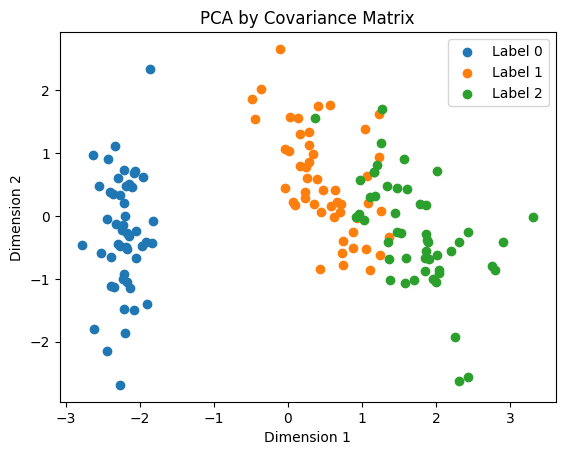

In [7]:
#given the opposite sign of the second eigenvector
#the viz looks like vertically flipped compared to sklearn
for i in np.unique(iris.target):
    plt.scatter(self_newdims_sigma[:,0][iris.target==i],
                self_newdims_sigma[:,1][iris.target==i],
                label=f'Label {int(i)}')
    
plt.title('PCA by Covariance Matrix')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend(loc=0)
plt.show()

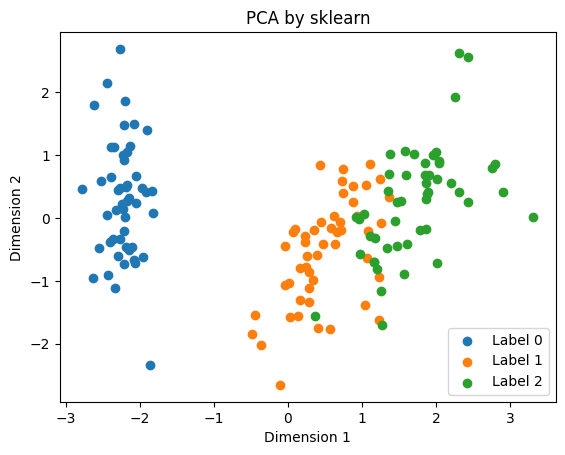

In [8]:
for i in np.unique(iris.target):
    plt.scatter(skl_newdims[:,0][iris.target==i],
                skl_newdims[:,1][iris.target==i],
                label=f'Label {int(i)}')
    
plt.title('PCA by sklearn')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend(loc=0)
plt.show()